## 1. Thiết Lập Môi Trường & Cấu Trúc Thư Mục Train

Cấu trúc thư mục `data/train/` gồm:
- `questions.jsonl`: 3,000 câu hỏi kèm `business_id` và `as_of_date`.
- `answers.jsonl`: 3,000 đáp án chuẩn (ground truth) tương ứng theo `id`.
- `calendar.csv`: Bảng tra cứu lịch dương - âm và các ngày nghỉ lễ/Tết.
- `rulebook.md`: Quy tắc nghiệp vụ mặc định (doanh thu, bán chạy, khoảng thời gian).
- `data/`: 30 thư mục con (`biz_101` đến `biz_130`) chứa file dữ liệu và `README.md`.

In [1]:
import os
import json
import glob
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Thiết lập đường dẫn tới thư mục dữ liệu train
TRAIN_DIR = Path('../data/train')
if not TRAIN_DIR.exists():
    TRAIN_DIR = Path('data/train')

DATA_BIZ_DIR = TRAIN_DIR / 'data'

print(f"Đường dẫn tập train: {TRAIN_DIR.resolve()}")
print("\nKiểm tra các thành phần trong thư mục train:")
for item in sorted(TRAIN_DIR.iterdir()):
    if item.is_dir():
        num_sub = len(list(item.iterdir()))
        print(f" - [DIR]  {item.name:<16} ({num_sub} doanh nghiệp)")
    else:
        size_kb = item.stat().st_size / 1024
        print(f" - [FILE] {item.name:<16} ({size_kb:8.1f} KB)")

Đường dẫn tập train: D:\Documents\Projects\datamate-zaic\data\train

Kiểm tra các thành phần trong thư mục train:
 - [FILE] answers.jsonl    (   238.5 KB)
 - [FILE] calendar.csv     (    43.0 KB)
 - [DIR]  data             (30 doanh nghiệp)
 - [FILE] questions.jsonl  (   492.3 KB)
 - [FILE] rulebook.md      (    18.1 KB)


---
## 2. Thống Kê Bộ Câu Hỏi & Kiểu Đáp Án (`questions.jsonl` & `answers.jsonl`)

Mỗi câu hỏi có:
- `id`: Mã định danh duy nhất.
- `business_id`: Doanh nghiệp tương ứng.
- `question`: Câu hỏi bằng tiếng Việt tự nhiên (có dấu/không dấu, cách viết tắt thông dụng).
- `as_of_date`: Ngày mốc giả định đóng vai trò "hôm nay".

Mỗi câu trả lời trong `answers.jsonl` thuộc 1 trong 8 kiểu dữ liệu (`type`):
1. `number`: Số nguyên / số thực làm tròn 2 chữ số thập phân (chiếm đa số ~62.8%).
2. `percent`: Tỷ lệ phần trăm làm tròn 2 chữ số (có dấu âm/dương ~19.3%).
3. `list`: Danh sách có thứ tự theo tiêu chí hỏi (~6.4%).
4. `date`: Ngày theo chuẩn `yyyy-mm-dd` hoặc tháng `yyyy-mm` (~4.8%).
5. `string`: Tên sản phẩm, khách hàng, chi nhánh, thứ trong tuần... (~2.9%).
6. `unanswerable`: Dữ liệu không đủ thông tin để trả lời (`answer = null`) (~2.3%).
7. `boolean`: `true` hoặc `false` (~0.8%).
8. `table`: Bảng dữ liệu nhỏ gồm `columns` và `rows` (~0.6%).

Tổng số câu hỏi: 3,000 câu hỏi từ 30 doanh nghiệp (mỗi doanh nghiệp đúng 100 câu)

Bảng phân bố các kiểu đáp án:
 Kiểu đáp án  Số lượng  Tỷ lệ (%)
      number      1884      62.80
     percent       578      19.27
        list       193       6.43
        date       145       4.83
      string        88       2.93
unanswerable        70       2.33
     boolean        23       0.77
       table        19       0.63


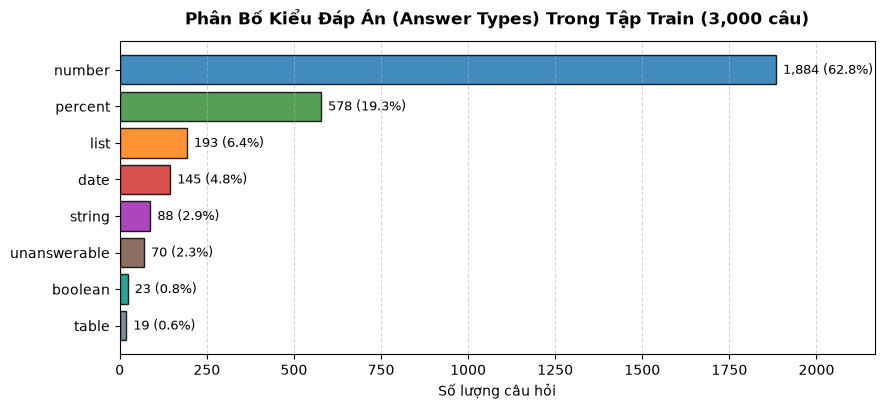

In [2]:
# Nạp questions.jsonl và answers.jsonl
with open(TRAIN_DIR / 'questions.jsonl', 'r', encoding='utf-8') as f:
    questions = [json.loads(line) for line in f]

with open(TRAIN_DIR / 'answers.jsonl', 'r', encoding='utf-8') as f:
    answers = [json.loads(line) for line in f]

df_q = pd.DataFrame(questions)
df_a = pd.DataFrame(answers)
df_train = pd.merge(df_q, df_a, on='id')

# Thống kê phân bố kiểu dữ liệu
type_counts = df_train['type'].value_counts()
type_df = pd.DataFrame({
    'Kiểu đáp án': type_counts.index,
    'Số lượng': type_counts.values,
    'Tỷ lệ (%)': (type_counts.values / len(df_train) * 100).round(2)
})

print(f"Tổng số câu hỏi: {len(df_train):,} câu hỏi từ {df_train['business_id'].nunique()} doanh nghiệp (mỗi doanh nghiệp đúng 100 câu)")
print("\nBảng phân bố các kiểu đáp án:")
print(type_df.to_string(index=False))

# Vẽ biểu đồ phân bố ngắn gọn, trực quan
plt.figure(figsize=(9, 4.2))
colors = ['#1f77b4', '#388e3c', '#ff7f0e', '#d32f2f', '#9c27b0', '#795548', '#009688', '#607d8b']
bars = plt.barh(type_df['Kiểu đáp án'][::-1], type_df['Số lượng'][::-1], color=colors[::-1], edgecolor='black', alpha=0.85)
plt.title('Phân Bố Kiểu Đáp Án (Answer Types) Trong Tập Train (3,000 câu)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Số lượng câu hỏi')
for bar in bars:
    w = bar.get_width()
    plt.text(w + 20, bar.get_y() + bar.get_height()/2, f"{w:,} ({w/len(df_train)*100:.1f}%)", va='center', fontsize=9)
plt.xlim(0, max(type_counts) * 1.15)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

---
## 3. Mẫu Câu Hỏi Điển Hình Cho Từng Kiểu Dữ Liệu

Dưới đây là một số ví dụ thực tế trong tập train đại diện cho từng loại đáp án để hình dung câu hỏi và định dạng trả về tương ứng.

In [3]:
# Hiển thị ví dụ đại diện cho từng kiểu đáp án
sample_types = ['number', 'percent', 'list', 'date', 'string', 'unanswerable', 'boolean', 'table']
samples = []
for t in sample_types:
    sub = df_train[df_train['type'] == t]
    if not sub.empty:
        row = sub.iloc[0]
        ans_str = str(row['answer'])
        if len(ans_str) > 55:
            ans_str = ans_str[:52] + '...'
        samples.append({
            'Type': t,
            'Business': row['business_id'],
            'Question': row['question'],
            'Ground Truth Answer': ans_str
        })

df_samples = pd.DataFrame(samples)
pd.set_option('display.max_colwidth', None)
print(df_samples.to_string(index=False))

        Type Business                                                                                         Question                                     Ground Truth Answer
      number  biz_128                                           tháng này tổng giá trị các phiếu nhập hàng là bao nhiu                                                89526400
     percent  biz_105                                                            tỉ lệ huỷ đơn tháng 6/2025 là nhiêu %                                                    2.08
        list  biz_124 dthu 3 tháng liền nhau kết thúc ở tháng 6/2025 là bao nhiêu mỗi tháng, từ tháng cũ đến tháng mới                       [287435200, 346554700, 309693800]
        date  biz_120                                               xem giup ngay nao trong thang 2/2025 dthu cao nhat                                              2025-02-15
      string  biz_114                                                                  thang 6/2025 hang nao chay nhat       

---
## 4. Mốc Thời Gian (`as_of_date`) & Lịch Âm Dương (`calendar.csv`)

- **`as_of_date`**: Điểm mốc giả định đóng vai trò "hôm nay". Mọi biểu thức tương đối như *"hôm qua"*, *"tuần rồi"*, *"tháng này"*, *"cùng kỳ năm ngoái"* đều phải tính toán tương đối so với mốc `as_of_date` của câu hỏi.
- **`calendar.csv`**: Cung cấp ánh xạ từng ngày dương lịch sang ngày/tháng/năm âm lịch và đánh dấu các ngày lễ/Tết (đặc biệt là kỳ nghỉ Tết Nguyên Đán từ 23 tháng Chạp đến mùng 10 tháng Giêng).

In [4]:
# Phân tích dải thời gian as_of_date
dates = pd.to_datetime(df_train['as_of_date'])
print(f"Khoảng thời gian as_of_date: từ {dates.min().strftime('%d/%m/%Y')} đến {dates.max().strftime('%d/%m/%Y')}")

# Khám phá cấu trúc file calendar.csv
df_cal = pd.read_csv(TRAIN_DIR / 'calendar.csv')
print(f"Tổng số ngày trong calendar.csv: {len(df_cal)} ngày (từ {df_cal['date'].min()} đến {df_cal['date'].max()})")

print("\nCác ngày lễ tiêu biểu trong calendar:")
holidays = df_cal[df_cal['holiday'].notna()][['date', 'weekday', 'lunar_day', 'lunar_month', 'holiday']].drop_duplicates(subset=['holiday'])
print(holidays.head(7).to_string(index=False))

Khoảng thời gian as_of_date: từ 15/01/2025 đến 20/09/2026
Tổng số ngày trong calendar.csv: 1461 ngày (từ 2024-01-01 đến 2027-12-31)

Các ngày lễ tiêu biểu trong calendar:
      date  weekday  lunar_day  lunar_month        holiday
2024-01-01        1         20           11 Tết Dương lịch
2024-02-10        6          1            1            Tết
2024-04-18        4         10            3         Giỗ tổ
2024-04-30        2         22            3           30/4
2024-05-01        3         23            3            1/5
2024-09-02        1         30            7            2/9
2024-09-17        2         15            8      Trung thu


---
## 5. Đặc Điểm Dữ Liệu 30 Doanh Nghiệp (`data/`)

Dữ liệu của 30 doanh nghiệp (`biz_101` đến `biz_130`) rất đa dạng về ngành nghề và định dạng lưu trữ:
- **Ngành nghề:** Tạp hóa, F&B (quán nước, quán ăn, trà sữa), nhà thuốc, vật liệu xây dựng, sửa chữa xe máy, mẹ & bé...
- **Định dạng file:** 
  + `.xlsx` (Excel): Phổ biến nhất (107 file), thường chia thành nhiều sheet theo tháng hoặc danh mục.
  + `.csv`: 20 file, dạng bảng phẳng giao dịch hoặc hệ thống bảng quan hệ.
  + `.sqlite`: 1 doanh nghiệp (`biz_123`), cơ sở dữ liệu quan hệ hoàn chỉnh.
- **`README.md`:** Mỗi doanh nghiệp đều có một file `README.md` tóm tắt ngành nghề, ý nghĩa các cột, trạng thái đơn hàng...

In [5]:
# Khảo sát dữ liệu 30 doanh nghiệp
biz_stats = []
for b_dir in sorted(DATA_BIZ_DIR.iterdir()):
    if b_dir.is_dir():
        files = [f for f in b_dir.iterdir() if f.name != 'README.md']
        exts = sorted(list(set(f.suffix for f in files)))
        total_size_mb = sum(f.stat().st_size for f in files) / (1024 * 1024)
        biz_stats.append({
            'Doanh nghiệp': b_dir.name,
            'Định dạng': ', '.join(exts),
            'Số file': len(files),
            'Dung lượng (MB)': round(total_size_mb, 2)
        })

df_biz = pd.DataFrame(biz_stats)

print(f"Tổng dung lượng dữ liệu 30 doanh nghiệp: {df_biz['Dung lượng (MB)'].sum():.2f} MB")
print(f"Dung lượng trung bình mỗi doanh nghiệp: {df_biz['Dung lượng (MB)'].mean():.2f} MB (nhỏ nhất: {df_biz['Dung lượng (MB)'].min()} MB, lớn nhất: {df_biz['Dung lượng (MB)'].max()} MB)")
print("\nPhân loại định dạng file trong 30 doanh nghiệp:")
print(df_biz['Định dạng'].value_counts().to_string())

print("\nTop 5 doanh nghiệp có dung lượng lớn nhất:")
print(df_biz.sort_values(by='Dung lượng (MB)', ascending=False).head(5).to_string(index=False))

Tổng dung lượng dữ liệu 30 doanh nghiệp: 184.44 MB
Dung lượng trung bình mỗi doanh nghiệp: 6.15 MB (nhỏ nhất: 1.2 MB, lớn nhất: 17.73 MB)

Phân loại định dạng file trong 30 doanh nghiệp:
Định dạng
.xlsx          21
.csv            7
.sqlite         1
.csv, .xlsx     1

Top 5 doanh nghiệp có dung lượng lớn nhất:
Doanh nghiệp   Định dạng  Số file  Dung lượng (MB)
     biz_123     .sqlite        1            17.73
     biz_124 .csv, .xlsx       13            13.40
     biz_106       .xlsx       10            12.88
     biz_111        .csv        5            11.40
     biz_129        .csv        5            10.56
